# Construct the forward variance curve

We construct smooth forward variance curves from SPX volatility smiles for the four reference dates: 

2024-12-19, 2025-04-16, 2025-06-20, and 2025-07-02. 

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from _calib_params import CALIB_DATES
from fwd_var_curve import xi_curve_smooth
from utils import var_swap_robust

COLORS = ("#1e732b", "#6b8203", "#b38a16", "#ed8e6e")

plt.rcdefaults()
plt.rcParams.update(
    {
        "font.size": 9,
        "axes.linewidth": 0.6,
        "legend.framealpha": 1,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

## Robust estimation of the variance contract

By definition, $\xi_t(u)=\mathbb{E}_t[V_u]$. The fair value of the variance contract is
$$M_t(T)=\int_t^T \xi_t(u)\,du,$$
so differentiating with respect to maturity gives $\xi_t(T)=\partial_T M_t(T)$.

We first estimate variance swaps from the volatility smiles, then fit the corresponding total variances.

## Smooth forward curve construction

We apply the smooth curve construction of Filipović and Willems, implemented by Rick Cao and Jim Gatheral, to the variance-swap curve. The resulting forward variance curve is piecewise quadratic.

In practice, input variance swaps are only known up to a bid-offer spread. The `EPS` parameter allows deviations in volatility units when smoothing the curve.

Smoothness alone does not guarantee a positive forward variance curve.

In [ ]:
EPS = 0.03

u = np.linspace(0, 0.2, 101)
curves = pd.DataFrame({"u": u})
for date in CALIB_DATES:
    spx = pd.read_csv(f"data/{date}_spx_vol.csv")
    swaps = var_swap_robust(spx)
    xi = xi_curve_smooth(
        swaps["expiries"], swaps["vs_mid"] * swaps["expiries"], eps=EPS
    )["xi_curve"]
    curves[date] = xi(u)

/Users/fbourgey/projects/QuadraticRoughHeston/src/utils.py:326: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  wbar_flat = quad(PchipInterpolator(np.sort(y_in), sig_in_y**2), y_min, y_max)[0]
/Users/fbourgey/projects/QuadraticRoughHeston/src/utils.py:326: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from spl

## Plot the forward variance curves

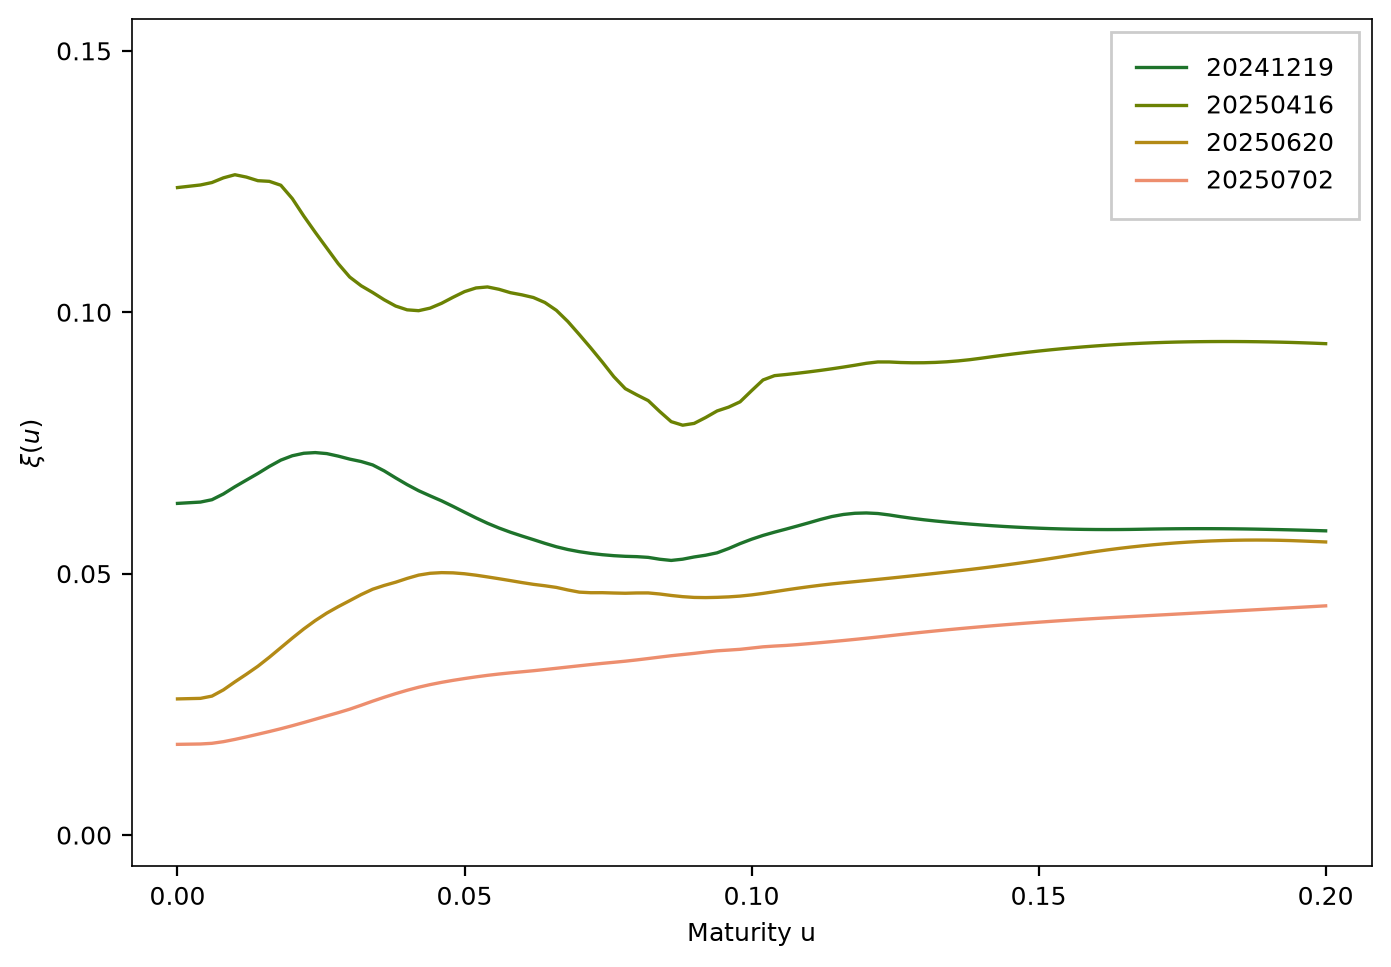

In [3]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for date, color in zip(CALIB_DATES, COLORS):
    ax.plot(curves.u, curves[date], color=color, label=date, linewidth=1.2)
ax.set(
    xlabel="Maturity u",
    ylabel=r"$\xi(u)$",
    xlim=(-0.008, 0.208),
    ylim=(-0.006, 0.156),
    xticks=np.linspace(0, 0.2, 5),
    yticks=np.linspace(0, 0.15, 4),
)
ax.legend(loc="upper right", fancybox=False, borderpad=1)
plt.show()